# Recover spatial programs in a simulated atlas
This tutorial fits SORT to the bundled eight-section atlas (10,368 locations
and 5,000 selected genes), then compares spatial recovery with PCA and NMF.
All methods use the same normalized expression and rank 24. Recovery is
measured by matching each true program to the component with the highest
signed Pearson correlation.

The input is included when you clone this repository. You can also
[download simulation.h5ad](https://raw.githubusercontent.com/zerovain/SORT_tutorial/main/data/simulation/simulation.h5ad)
and save it under `data/simulation/` in the tutorial repository.

In [1]:
from pathlib import Path
from time import perf_counter
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from sklearn.decomposition import NMF, PCA
import sort

plt.rcParams.update({"font.family": "sans-serif", "font.size": 8,
                     "pdf.fonttype": 42, "svg.fonttype": "none"})
output = Path("../outputs/simulation")
output.mkdir(parents=True, exist_ok=True)

## 1. Load and normalize the atlas

Load the included atlas. Its stored graph connects locations within sections
and has no edges between sections. No new feature selection is required.

In [3]:
adata = sc.read_h5ad(Path("../data/simulation/simulation.h5ad"))
adata

AnnData object with n_obs × n_vars = 10368 × 5000
    obs: 'sample_id', 'family_name', 'sample_subtype_idx', 'sample_subtype', 'core_region', 'dominant_region', 'dominant_subtype', 'core_mask', 'region_1_mask', 'region_2_mask', 'slice_index', 'spot_id', 'size_factor'
    var: 'Gene', 'BaseGeneMean', 'OutlierFactor', 'GeneMean', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'F_true', 'L_true', 'gep_names', 'hvg', 'sim_params', 'spatial_laplacian', 'tutorial_input'
    obsm: 'spatial'

Normalize counts using the stored scran size factors and the transformation
used in the simulation benchmark.

In [4]:
size_factor = adata.obs["size_factor"].to_numpy(float)
adata.X = adata.X.astype(np.float32).multiply(
    (np.median(size_factor) / size_factor)[:, None]
).tocsr()
adata.X.data = np.log(10.0 * (adata.X.data + 0.1)).astype(np.float32)

## 2. Fit SORT

Fit SORT with one background and 23 signal components. `device="numpy"`
makes this example runnable without a GPU. Use `"auto"` or `"cuda"` for GPU.

In [5]:
result = sort.fit(
    adata,
    n_components=24,
    alpha=1.0,
    lambda_l1_W=0.5,
    stage1_epochs=100,
    device="numpy",
    init_kwargs={"alpha": 10.0, "lambda2": 1e-8},
)
result

SORT: 10,368 locations x 5,000 genes; 24 components; device=numpy


Using 5000 / 5000 HVGs
Initializing activities and profiles...


Stage 1: orthogonal Procrustes updates (100 epochs)


  Stage 1: 10/100 epochs


  Stage 1: 20/100 epochs


...

  Stage 2: 80/100 epochs


  Stage 2: 90/100 epochs


  Stage 2: 100/100 epochs


Finished in 77.4 s
Stored .obsm['X_sort'] (10368, 24) and .varm['sort_signatures'] (5000, 24)


SORTResult(W=(10368, 24) spots_x_components, Q=(5000, 24) genes_x_components, background_component=0, fit_time=77.4s)

## 3. Compare with PCA and NMF

Fit PCA and NMF at rank 24. PCA centers expression, and NMF uses nonnegative
expression with NNDSVDa initialization and a maximum of 500 iterations.
Dense input for these baselines needs about 0.4GB before temporary arrays.

In [6]:
X_dense = np.asarray(adata.X.toarray(), dtype=np.float64)
print("Fitting PCA...", flush=True)
started = perf_counter()
pca = PCA(n_components=24, random_state=42)
W_pca = pca.fit_transform(X_dense - X_dense.mean(axis=0, keepdims=True))
pca_seconds = perf_counter() - started
print(f"PCA finished in {pca_seconds:.1f} s")

started = perf_counter()
print("Fitting NMF (maximum 500 iterations)...", flush=True)
nmf = NMF(n_components=24, init="nndsvda", max_iter=500, random_state=42)
W_nmf = nmf.fit_transform(np.clip(X_dense, 0, None))
nmf_seconds = perf_counter() - started
print(f"NMF finished in {nmf_seconds:.1f} s ({nmf.n_iter_} iterations)")
del X_dense

Fitting PCA...


PCA finished in 1.1 s
Fitting NMF (maximum 500 iterations)...


sklearn/decomposition/_nmf.py:1710: ConvergenceWarning: Maximum number of iterations 500 reached. Increase it to improve convergence.
  warnings.warn(


NMF finished in 32.0 s (500 iterations)


### Match recovered components to the true programs

To compare recovery, match each true program independently to the component with the
highest signed Pearson correlation across all locations. SORT signal
components start at index 1; PCA and NMF component indices start at 0.

In [7]:
truth = np.asarray(adata.uns["L_true"], dtype=float)
program_names = np.asarray(adata.uns["gep_names"], dtype=str)
activities = {"SORT": result.W[:, 1:], "PCA": W_pca, "NMF": W_nmf}


def rescale_columns(values):
    values = np.asarray(values, dtype=float)
    span = np.ptp(values, axis=0, keepdims=True)
    return np.divide(values - values.min(axis=0, keepdims=True), span,
                     out=np.zeros_like(values), where=span > 0)


def match_programs(activity, method):
    true_scaled, inferred = rescale_columns(truth), rescale_columns(activity)
    true_scaled -= true_scaled.mean(axis=0, keepdims=True)
    inferred -= inferred.mean(axis=0, keepdims=True)
    denominator = np.linalg.norm(true_scaled, axis=0)[:, None] * np.linalg.norm(inferred, axis=0)[None, :]
    correlation = np.divide(true_scaled.T @ inferred, denominator,
                            out=np.zeros((truth.shape[1], inferred.shape[1])), where=denominator > 0)
    matches = correlation.argmax(axis=1)
    return pd.DataFrame({"method": method, "program": program_names,
        "program_type": [name.split("_", 1)[0] for name in program_names],
        "matched_component": matches + (1 if method == "SORT" else 0),
        "recovery": correlation[np.arange(truth.shape[1]), matches]})


comparison_table = pd.concat([match_programs(values, method) for method, values in activities.items()], ignore_index=True)
recovery_table = comparison_table[comparison_table["method"] == "SORT"].rename(columns={"matched_component": "matched_gep"})
matched_gep = recovery_table["matched_gep"].to_numpy()
recovery = recovery_table["recovery"].to_numpy()
comparison_table.pivot(index="program", columns="method", values="recovery")

method,NMF,PCA,SORT
program,,,
patient_0,0.853062,0.596571,0.994983
patient_1,0.855508,0.371040,0.995026
patient_2,0.845085,0.688960,0.992755
patient_3,0.873610,0.691932,0.994773
patient_4,0.859800,0.595741,0.994633
patient_5,0.858731,0.437728,0.993322
patient_6,0.834635,0.574351,0.992329
patient_7,0.822510,0.481130,0.986607
region_1,0.855842,0.035285,0.990905


## 4. Inspect spatial recovery

Plot all 13 true programs alongside the best-matched component for each
method. Each map is min–max scaled to highlight its spatial pattern.

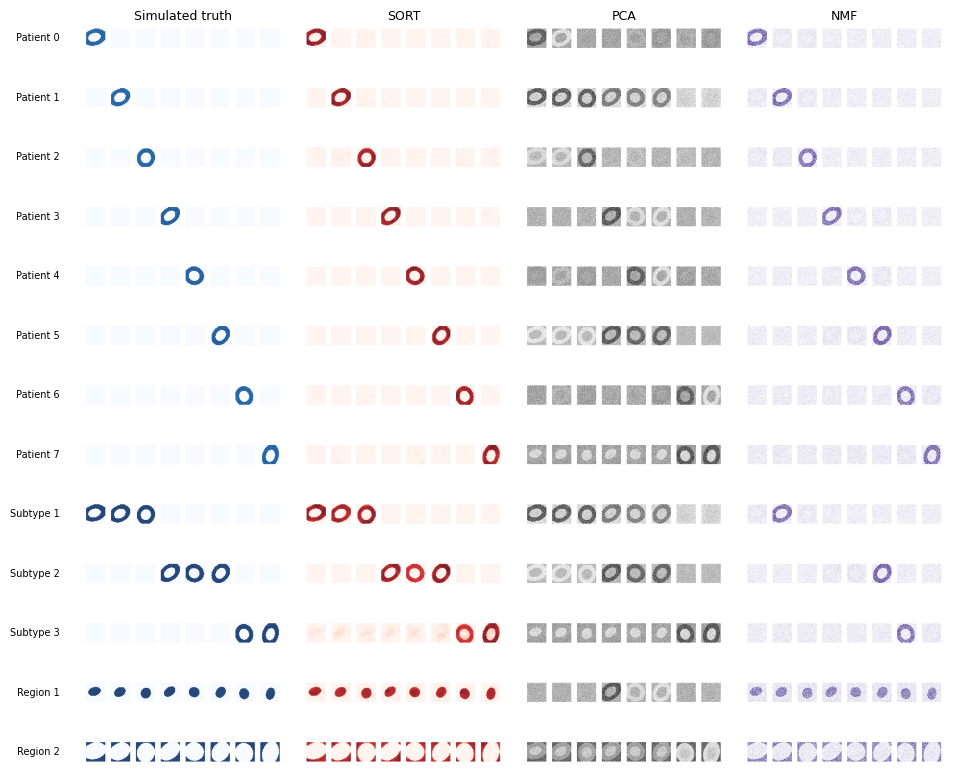

In [8]:
coords = np.asarray(adata.obsm["spatial"])
fig, axes = plt.subplots(len(program_names), 4, figsize=(10.4, 8.2))
for row, name in enumerate(program_names):
    maps = [(truth[:, row], "Blues")]
    for method, cmap in [("SORT", "Reds"), ("PCA", "Greys"), ("NMF", "Purples")]:
        match = comparison_table.loc[(comparison_table["method"] == method) & (comparison_table["program"] == name), "matched_component"].iloc[0]
        maps.append((result.W[:, match] if method == "SORT" else activities[method][:, match], cmap))
    for column, (values, cmap) in enumerate(maps):
        axes[row, column].scatter(coords[:, 0], coords[:, 1],
            c=rescale_columns(np.asarray(values)[:, None]).ravel(), s=0.32,
            cmap=cmap, vmin=0, vmax=1, linewidths=0, rasterized=True)
        axes[row, column].set_aspect("equal")
        axes[row, column].axis("off")
    axes[row, 0].text(-0.08, 0.5, name.replace("_", " ").title(),
        transform=axes[row, 0].transAxes, ha="right", va="center", fontsize=7)
for ax, title in zip(axes[0], ["Simulated truth", "SORT", "PCA", "NMF"]):
    ax.set_title(title, fontsize=9)
fig.subplots_adjust(left=0.15, right=0.99, top=0.96, bottom=0.02, hspace=0.04, wspace=0.04)
fig.savefig(output / "spatial_comparison.pdf", bbox_inches="tight")
fig.savefig(output / "spatial_comparison.svg", bbox_inches="tight")
fig.savefig(output / "spatial_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

### Summarize recovery by program type

Next, compare correlations for patient-specific, subtype-shared and regional
programs. Points are individual programs in this replicate (8 patient-specific,
3 subtype-shared and 2 regional programs). Horizontal bars are means within
each class.

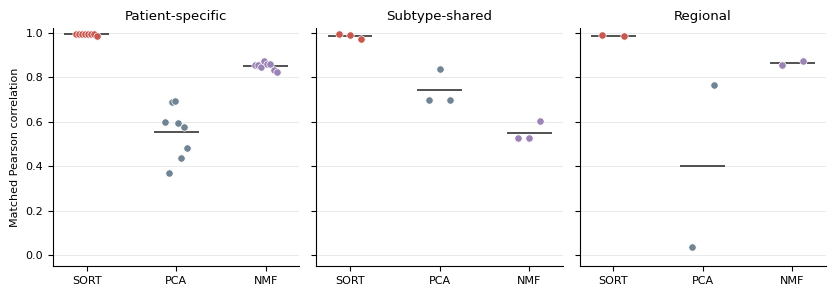

In [9]:
methods = ["SORT", "PCA", "NMF"]
colors = ["#C9574E", "#718493", "#9B83B5"]
fig, axes = plt.subplots(1, 3, figsize=(8.4, 3.0), sharey=True)
for ax, group, title in zip(axes, ["patient", "subtype", "region"], ["Patient-specific", "Subtype-shared", "Regional"]):
    for x, (method, color) in enumerate(zip(methods, colors)):
        values = comparison_table.loc[(comparison_table["method"] == method) & (comparison_table["program_type"] == group), "recovery"].to_numpy()
        ax.scatter(x + np.linspace(-0.12, 0.12, len(values)), values, s=28,
                   color=color, edgecolor="white", linewidth=0.5, zorder=3)
        ax.hlines(values.mean(), x - 0.25, x + 0.25, color="#222222", linewidth=1.1)
    ax.set_xticks(range(3), methods)
    ax.set_title(title)
    ax.set_ylim(-0.05, 1.02)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", color="#E6E6E6", linewidth=0.6)
axes[0].set_ylabel("Matched Pearson correlation")
fig.tight_layout()
fig.savefig(output / "recovery_comparison.pdf", bbox_inches="tight")
fig.savefig(output / "recovery_comparison.svg", bbox_inches="tight")
fig.savefig(output / "recovery_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Save the results

Save matrices, names, parameters, recovery values and baseline timings.
Figures are exported as PDF, SVG and PNG for reuse.

In [10]:
result.save(str(output / "sort_matrices"))
np.savez_compressed(output / "baseline_activities.npz", W_pca=W_pca, W_nmf=W_nmf)
comparison_table.to_csv(output / "recovery_comparison.csv", index=False)
(output / "timings.json").write_text(json.dumps({"sort_seconds": result.metadata["fit_time_seconds"],
    "pca_seconds": pca_seconds, "nmf_seconds": nmf_seconds,
    "nmf_iterations": int(nmf.n_iter_), "rank": 24, "baseline_seed": 42}, indent=2))
print(f"Outputs saved to {output}")

Outputs saved to ../outputs/simulation
